<a href="https://colab.research.google.com/github/siaelkhattat/SuperResolution/blob/main/notebooks/03_edsr_lite.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
if not os.path.exists("/content/SuperResolution"):
    !git clone https://github.com/siaelkhattat/SuperResolution.git
%cd /content/SuperResolution
!git pull
!pip install -q -r requirements.txt
from google.colab import drive; drive.mount("/content/drive")

Cloning into 'SuperResolution'...
remote: Enumerating objects: 76, done.
remote: Counting objects: 100% (76/76), done.
remote: Compressing objects: 100% (59/59), done.
remote: Total 76 (delta 15), reused 64 (delta 9), pack-reused 0 (from 0)
Receiving objects: 100% (76/76), 2.33 MiB | 24.05 MiB/s, done.
Resolving deltas: 100% (15/15), done.
/content/SuperResolution
Already up to date.
Mounted at /content/drive


In [ ]:
!mkdir -p data/raw
!wget -4 -c --progress=dot:giga -O data/raw/DIV2K_train_HR.zip http://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_train_HR.zip
!unzip -q data/raw/DIV2K_train_HR.zip -d data/raw
!ls data/raw/DIV2K_train_HR | wc -l          # expected: 800
!python data/download.py                      # skips DIV2K (already there) and fetches Set5/Set14

--2026-11-16 14:07:14--  http://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_train_HR.zip
Resolving data.vision.ee.ethz.ch (data.vision.ee.ethz.ch)... 129.132.52.178
Connecting to data.vision.ee.ethz.ch (data.vision.ee.ethz.ch)|129.132.52.178|:80... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_train_HR.zip [following]
--2026-11-16 14:08:22--  https://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_train_HR.zip
Connecting to data.vision.ee.ethz.ch (data.vision.ee.ethz.ch)|129.132.52.178|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 3530603713 (3.3G) [application/zip]
Saving to: ‘data/raw/DIV2K_train_HR.zip’

     0K ........ ........ ........ ........  0% 20.0M 2m46s
 32768K ........ ........ ........ ........  1% 33.0M 2m12s
 65536K ........ ........ ........ ........  2% 33.0M 2m1s
 98304K ........ ........ ........ ........  3% 36.4M 1m52s
131072K ........ ........ ........ ........  4% 32.7M 1m48s


In [ ]:
!ls data/raw/DIV2K_train_HR | wc -l      # 400
!ls data/raw/Set5 | wc -l                # 5
!ls data/raw/Set14 | wc -l               # 14
!nvidia-smi | head -n 12                 # confirm a T4 is attached

800
5
14
Mon Nov 16 14:12:42 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+--------------------------------------

In [ ]:
!python -m src.train.train_cnn --config configs/cnn.yaml

caching train images: 0it [00:00, ?it/s]
Traceback (most recent call last):
  File "<frozen runpy>", line 203, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/content/SuperResolution/src/train/train_cnn.py", line 65, in <module>
    train(ap.parse_args().config)
    ~~~~~^^^^^^^^^^^^^^^^^^^^^^^^
  File "/content/SuperResolution/src/train/train_cnn.py", line 29, in train
    loader = DataLoader(train_ds, batch_size=cfg["batch_size"], shuffle=True,
                        num_workers=0, drop_last=True)
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 401, in __init__
    sampler = RandomSampler(dataset, generator=generator)  # type: ignore[arg-type]
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/sampler.py", line 149, in __init__
    raise ValueError(
        f"num_samples should be a positive integer value, but got num_samples={self.num_samples}"
    )
ValueError: num_samples should be a positive integ

In [ ]:
%cd /content/SuperResolution
!wc -c data/splits/*.txt            # size in bytes: 0 means empty
!git log --oneline -- data/splits   # history of the splits in git

/content/SuperResolution
0 data/splits/test.txt
0 data/splits/train.txt
0 data/splits/val.txt
0 total
5f6efd1 SDSR-lite model and training script


In [ ]:
!git pull
!python -m src.data.split
!wc -l data/splits/*.txt

remote: Enumerating objects: 9, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (1/1), done.
remote: Total 5 (delta 4), reused 5 (delta 4), pack-reused 0 (from 0)
Unpacking objects: 100% (5/5), 714 bytes | 714.00 KiB/s, done.
From https://github.com/siaelkhattat/SuperResolution
   917dea0..c0346ff  main       -> origin/main
Updating 917dea0..c0346ff
Fast-forward
 src/data/split.py | 20 ++++++++++++++------
 1 file changed, 14 insertions(+), 6 deletions(-)
{'train': 300, 'val': 50, 'test': 50}
  49 data/splits/test.txt
 299 data/splits/train.txt
  49 data/splits/val.txt
 397 total


In [ ]:
!python -m src.data.check_leakage
!git status --short data/splits
!tar -tf /content/drive/MyDrive/sr_low_cost/data/sr_data.tar | grep -c DIV2K

OK : aucun chevauchement, aucune fuite vers Set5/Set14
tar: /content/drive/MyDrive/sr_low_cost/data/sr_data.tar: Cannot open: No such file or directory
tar: Error is not recoverable: exiting now
0


In [ ]:
from google.colab import drive; drive.mount("/content/drive")
!ls -lh /content/drive/MyDrive/sr_low_cost/ /content/drive/MyDrive/sr_low_cost/data/ 2>&1

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ls: cannot access '/content/drive/MyDrive/sr_low_cost/': No such file or directory
ls: cannot access '/content/drive/MyDrive/sr_low_cost/data/': No such file or directory


In [ ]:
!ls -lh /content/drive/MyDrive/sr_low_cost/ /content/drive/MyDrive/sr_low_cost/data/ 2>&1

/content/drive/MyDrive/sr_low_cost/:
total 8.0K
drwx------ 2 root root 4.0K Nov 16 14:18 checkpoints
drwx------ 2 root root 4.0K Nov 16 18:35 data

/content/drive/MyDrive/sr_low_cost/data/:
total 0
-rw------- 1 root root 0 Nov 16 18:34 sr_data.tar


In [ ]:
!python -m src.train.train_cnn --config configs/cnn.yaml

caching train images: 100% 300/300 [00:32<00:00,  9.13it/s]
params (M): 0.926723
{'epoch': 1, 'l1': 0.030485483210155352, 'val_psnr': nan, 'minutes': 0.2}
{'epoch': 2, 'l1': 0.028400629798677517, 'val_psnr': nan, 'minutes': 0.3}
{'epoch': 3, 'l1': 0.028485903645900482, 'val_psnr': nan, 'minutes': 0.4}
{'epoch': 4, 'l1': 0.02846501582864931, 'val_psnr': nan, 'minutes': 0.6}
{'epoch': 5, 'l1': 0.02804653716577406, 'val_psnr': nan, 'minutes': 0.7}
{'epoch': 6, 'l1': 0.02786844102217552, 'val_psnr': nan, 'minutes': 0.8}
{'epoch': 7, 'l1': 0.027499824777285364, 'val_psnr': nan, 'minutes': 0.9}
{'epoch': 8, 'l1': 0.027604224598583055, 'val_psnr': nan, 'minutes': 1.1}
{'epoch': 9, 'l1': 0.02727823130746576, 'val_psnr': nan, 'minutes': 1.2}
{'epoch': 10, 'l1': 0.027277979451943848, 'val_psnr': 28.602495193481445, 'minutes': 1.3}
{'epoch': 11, 'l1': 0.02719753489077569, 'val_psnr': nan, 'minutes': 1.8}
{'epoch': 12, 'l1': 0.026194330065805006, 'val_psnr': nan, 'minutes': 1.9}
{'epoch': 13, 'l1'

In [8]:
import sys; sys.path.insert(0, ".")
import torch, pandas as pd
from src.models.edsr_lite import EDSRLite
from src.eval.evaluate import get_datasets, evaluate_method, summarize

device = "cuda"
ckpt = torch.load("/content/drive/MyDrive/sr_low_cost/checkpoints/edsr_lite_best.pth", map_location=device)
model = EDSRLite(**ckpt["arch"]); model.load_state_dict(ckpt["model"])
print("best epoch:", ckpt["epoch"], "| val PSNR:", round(ckpt["val_psnr"], 3))

datasets = get_datasets()
df = evaluate_method("edsr_lite_100ep", model, datasets, device=device)
df.to_csv("results/tables/per_image_edsr_lite_100ep.csv", index=False)
all_df = pd.concat([pd.read_csv("results/tables/per_image_bicubic.csv"), df])
summarize(all_df)

best epoch: 100 | val PSNR: 28.983


edsr_lite_100ep on Set5:   0%|          | 0/5 [00:00<?, ?it/s]

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth



  0%|          | 0.00/233M [00:00<?, ?B/s]
  7%|▋         | 17.4M/233M [00:00<00:01, 182MB/s]
 15%|█▌        | 35.2M/233M [00:00<00:01, 184MB/s]
 23%|██▎       | 53.0M/233M [00:00<00:01, 185MB/s]
 31%|███▏      | 73.0M/233M [00:00<00:00, 195MB/s]
 40%|████      | 94.4M/233M [00:00<00:00, 205MB/s]
 49%|████▉     | 114M/233M [00:00<00:00, 160MB/s] 
 56%|█████▌    | 131M/233M [00:00<00:00, 152MB/s]
 63%|██████▎   | 146M/233M [00:00<00:00, 154MB/s]
 69%|██████▉   | 162M/233M [00:01<00:00, 154MB/s]
 77%|███████▋  | 180M/233M [00:01<00:00, 165MB/s]
 85%|████████▌ | 198M/233M [00:01<00:00, 173MB/s]
100%|██████████| 233M/233M [00:01<00:00, 174MB/s]


Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth


edsr_lite_100ep on DIV2K_test: 100%|██████████| 50/50 [00:36<00:00,  1.36it/s]


,method,dataset,psnr,ssim,lpips
0,bicubic,DIV2K_test,28.4458,0.8023,0.3886
1,bicubic,Set14,26.2199,0.7263,0.4433
2,bicubic,Set5,28.6347,0.8265,0.3419
3,edsr_lite_100ep,DIV2K_test,29.5146,0.8380,0.2982
4,edsr_lite_100ep,Set14,27.7839,0.7797,0.3241
5,edsr_lite_100ep,Set5,30.9010,0.8847,0.2083


In [9]:
from src.eval.benchmark_speed import benchmark
speed = pd.concat([benchmark("edsr_lite", model, device="cuda"),
                   benchmark("edsr_lite", model, device="cpu")])
speed.to_csv("results/tables/speed_edsr_lite.csv", index=False); speed

,method,device,lr_size,ms_median,ms_std,peak_mem_mb,params_m
0,edsr_lite,cuda,64x64,5.415,0.596,54.0,0.927
1,edsr_lite,cuda,256x256,48.723,0.344,549.7,0.927
0,edsr_lite,cpu,64x64,131.834,14.289,NaN,0.927
1,edsr_lite,cpu,256x256,2785.065,479.118,NaN,0.927


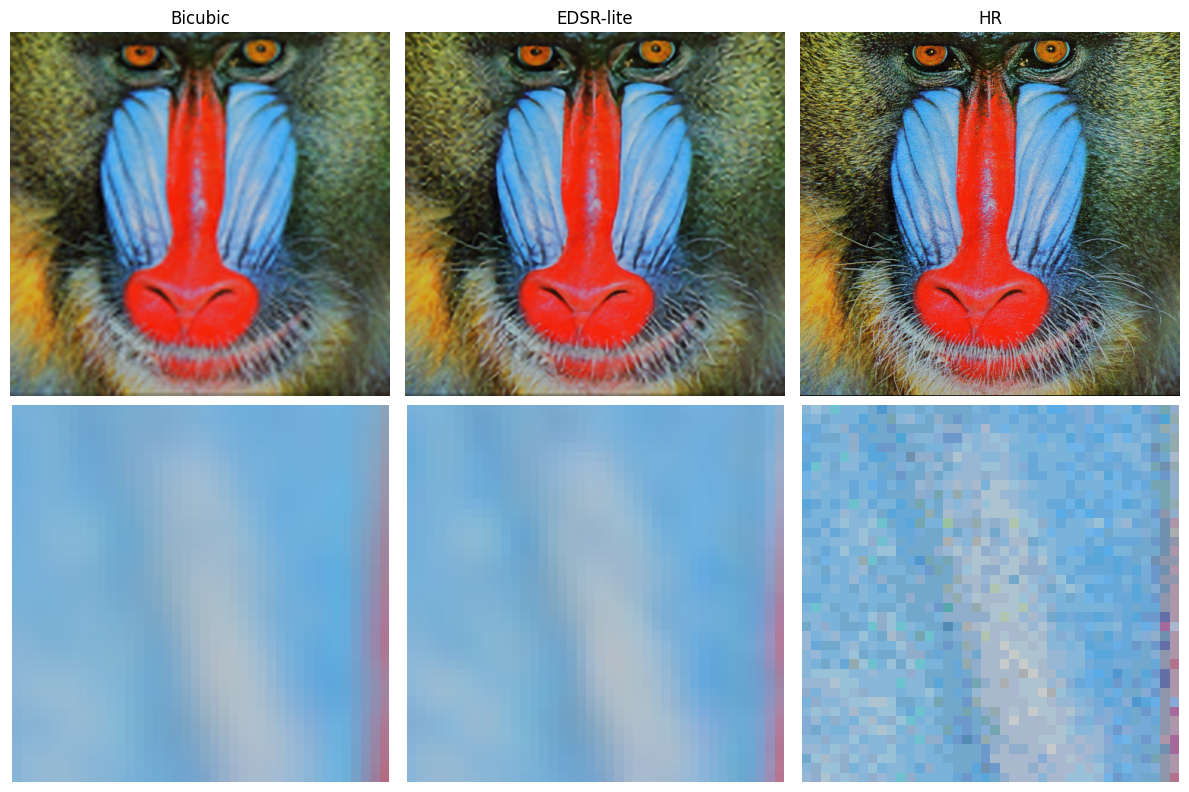

In [10]:
import matplotlib.pyplot as plt
from src.models.bicubic import Bicubic
from src.eval.evaluate import to_np

ds = datasets["Set14"]; lr, hr = ds[0]
model.cpu().eval()
outs = {"Bicubic": Bicubic(4)(lr[None])[0], "EDSR-lite": model(lr[None])[0], "HR": hr}
h, w = hr.shape[1:]; y, x, s = h // 3, w // 3, 40
fig, ax = plt.subplots(2, 3, figsize=(12, 8))
for j, (t, im) in enumerate(outs.items()):
    ax[0, j].imshow(to_np(im)); ax[0, j].set_title(t); ax[0, j].axis("off")
    ax[1, j].imshow(to_np(im)[y:y+s, x:x+s], interpolation="nearest"); ax[1, j].axis("off")
plt.tight_layout(); plt.savefig("results/figures/bicubic_vs_edsr_zoom.png", dpi=150); plt.show()

In [ ]:
import os
if not os.path.exists("/content/SuperResolution"):
    !git clone https://github.com/siaelkhattat/SuperResolution.git
%cd /content/SuperResolution
!git pull
!pip install -q -r requirements.txt
import sys; sys.path.insert(0, ".")
from src.utils.colab_setup import setup_data
setup_data()

/content/SuperResolution
Already up to date.


CalledProcessError: Command '['tar', '-xf', '/content/sr_data.tar', '-C', 'data/raw']' returned non-zero exit status 2.

In [ ]:
!ls -lh /content/drive/MyDrive/sr_low_cost/data/sr_data.tar /content/sr_data.tar
!tar -tf /content/sr_data.tar | tail -n 3
!df -h /content | tail -n 1

-rw------- 1 root root 0 Nov 16 18:34 /content/drive/MyDrive/sr_low_cost/data/sr_data.tar
-rw------- 1 root root 0 Nov 16 18:40 /content/sr_data.tar
tar: This does not look like a tar archive
tar: Exiting with failure status due to previous errors
overlay         113G  100M  113G   1% /


In [ ]:
%cd /content/SuperResolution
!rm -f src/utils/colab_setup.py
!git pull
!grep -c "def " src/utils/colab_setup.py     # expected: 9 functions (the new version)

/content/SuperResolution
Updating c0346ff..538dc96
Fast-forward
 src/utils/colab_setup.py | 111 +++++++++++++++++++++++++++++++++++++++++++++++
 1 file changed, 111 insertions(+)
 create mode 100644 src/utils/colab_setup.py
8


In [2]:
import os
if not os.path.exists("/content/SuperResolution"):
    !git clone https://github.com/siaelkhattat/SuperResolution.git
%cd /content/SuperResolution
!git pull
!pip install -q -r requirements.txt
import sys; sys.path.insert(0, ".")
from src.utils.colab_setup import (mount_drive, setup_data, restore_results_from_drive,
                                   verify_repo, load_generator, sync_results_to_drive, CKPT_DIR)
mount_drive(); setup_data(); restore_results_from_drive(); verify_repo()

/content/SuperResolution
Already up to date.
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


RuntimeError: Archive on Drive is corrupt: rebuild it.
tar: This does not look like a tar archive
tar: Exiting with failure status due to previous errors


In [3]:
!rm -f /content/drive/MyDrive/sr_low_cost/data/sr_data.tar /content/drive/MyDrive/sr_low_cost/data/sr_data.tar.part /content/sr_data.tar

In [4]:
!mkdir -p data/raw
!wget -4 -c --progress=dot:giga -O data/raw/DIV2K_train_HR.zip http://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_train_HR.zip

--2026-11-16 18:51:46--  http://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_train_HR.zip
Resolving data.vision.ee.ethz.ch (data.vision.ee.ethz.ch)... 129.132.52.178
Connecting to data.vision.ee.ethz.ch (data.vision.ee.ethz.ch)|129.132.52.178|:80... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_train_HR.zip [following]
--2026-11-16 18:51:47--  https://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_train_HR.zip
Connecting to data.vision.ee.ethz.ch (data.vision.ee.ethz.ch)|129.132.52.178|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 3530603713 (3.3G) [application/zip]
Saving to: ‘data/raw/DIV2K_train_HR.zip’

     0K ........ ........ ........ ........  0% 13.0M 4m17s
 32768K ........ ........ ........ ........  1% 21.4M 3m24s
 65536K ........ ........ ........ ........  2% 23.9M 3m0s
 98304K ........ ........ ........ ........  3% 21.5M 2m52s
131072K ........ ........ ........ ........  4% 21.5M 2m46s


In [5]:
!unzip -q data/raw/DIV2K_train_HR.zip -d data/raw
!ls data/raw/DIV2K_train_HR | wc -l          # expected: 800
!python data/download.py                      # skips DIV2K, fetches Set5 and Set14
!ls data/raw/Set5 | wc -l                     # expected: 5
!ls data/raw/Set14 | wc -l                    # expected: 14

800
DIV2K prêt : 800 images

data/Set5_HR.tar.gz: downloading bytes:   0% 0.00/852k [00:00<?, ?B/s]
data/Set5_HR.tar.gz: downloading bytes: 100% 852k/852k [00:01<00:00, 580kB/s, 81.8kB/s  ]
data/Set5_HR.tar.gz: reconstructing file: 100% 852k/852k [00:01<00:00, 580kB/s, 81.8kB/s  ]
/content/SuperResolution/data/download.py:34: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tf.extractall(tmp)
Set5 : 5 HR images

data/Set14_HR.tar.gz: downloading bytes:  34% 1.71M/4.98M [00:01<00:02, 1.38MB/s]
data/Set14_HR.tar.gz: downloading bytes: 100% 4.98M/4.98M [00:01<00:00, 3.30MB/s,  478kB/s  ]
data/Set14_HR.tar.gz: reconstructing file: 100% 4.98M/4.98M [00:01<00:00, 3.30MB/s,  479kB/s  ]
Set14 : 14 HR images
5
14


In [6]:
from src.utils.colab_setup import build_data_archive
build_data_archive()

Archive OK: (400, 5, 14) | 1.65 GB


In [7]:
model, ck = load_generator("edsr_lite_best")
print("epoch", ck["epoch"], "| val PSNR:", round(ck["val_psnr"], 3))   # expected: ~28.98

epoch 100 | val PSNR: 28.983


In [11]:
!zip -r colab_outputs3.zip results/tables results/figures
from google.colab import files
files.download("colab_outputs3.zip")

  adding: results/tables/ (stored 0%)
  adding: results/tables/speed_edsr_lite.csv (deflated 40%)
  adding: results/tables/summary_bicubic.csv (deflated 22%)
  adding: results/tables/per_image_edsr_lite_100ep.csv (deflated 62%)
  adding: results/tables/speed_bicubic.csv (deflated 38%)
  adding: results/tables/per_image_bicubic.csv (deflated 59%)
  adding: results/figures/ (stored 0%)
  adding: results/figures/bicubic_zoom_example.png (deflated 1%)
  adding: results/figures/bicubic_vs_edsr_zoom.png (deflated 0%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>